In [10]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import pickle
import cv2
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import kagglehub


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [11]:
print("Downloading dataset...")
dataset_path = kagglehub.dataset_download("mohamedasak/chest-x-ray-6-classes-dataset")
print(f"Dataset path: {dataset_path}")


def find_subdir(root, target):
    for dirpath, dirnames, filenames in os.walk(root):
        for d in dirnames:
            if target.lower() in d.lower():
                return os.path.join(dirpath, d)
    return None

train_path = find_subdir(dataset_path, "train")
val_path = find_subdir(dataset_path, "val")
test_path = find_subdir(dataset_path, "test")

print(f"Train: {train_path}")
print(f"Val: {val_path}")
print(f"Test: {test_path}")


CLASS_NAMES = sorted(os.listdir(train_path))
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

Using Colab cache for faster access to the 'chest-x-ray-6-classes-dataset' dataset.
Dataset path: /kaggle/input/chest-x-ray-6-classes-dataset
Train: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/train
Val: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/val
Test: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/test
Classes (6): ['Covid-19', 'Emphysema', 'Normal', 'Pneumonia-Bacterial', 'Pneumonia-Viral', 'Tuberculosis']


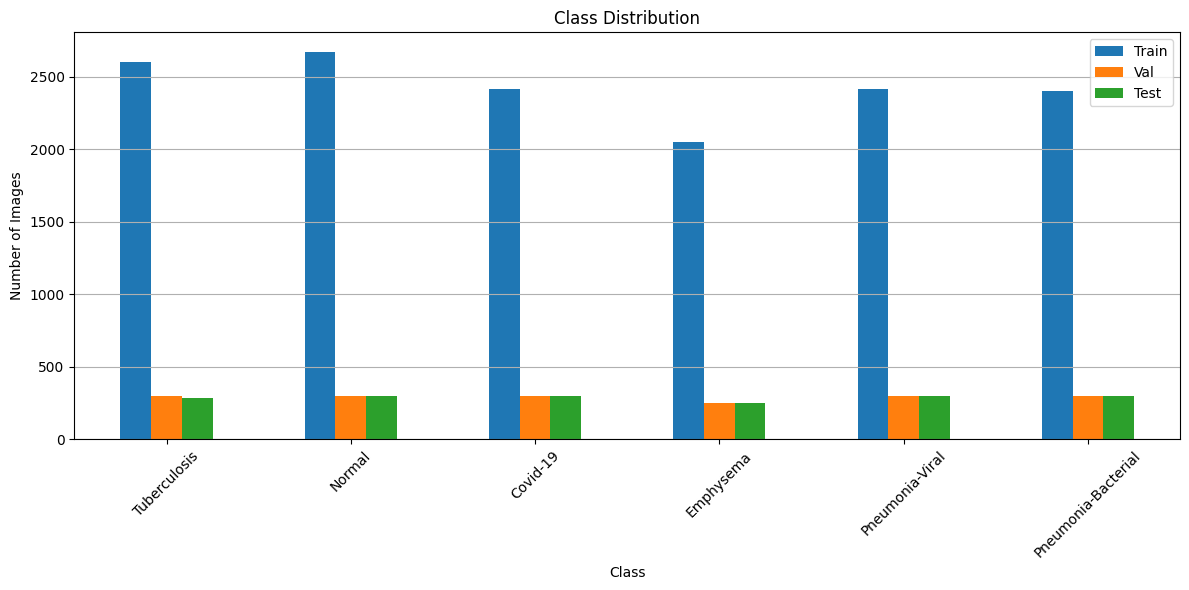

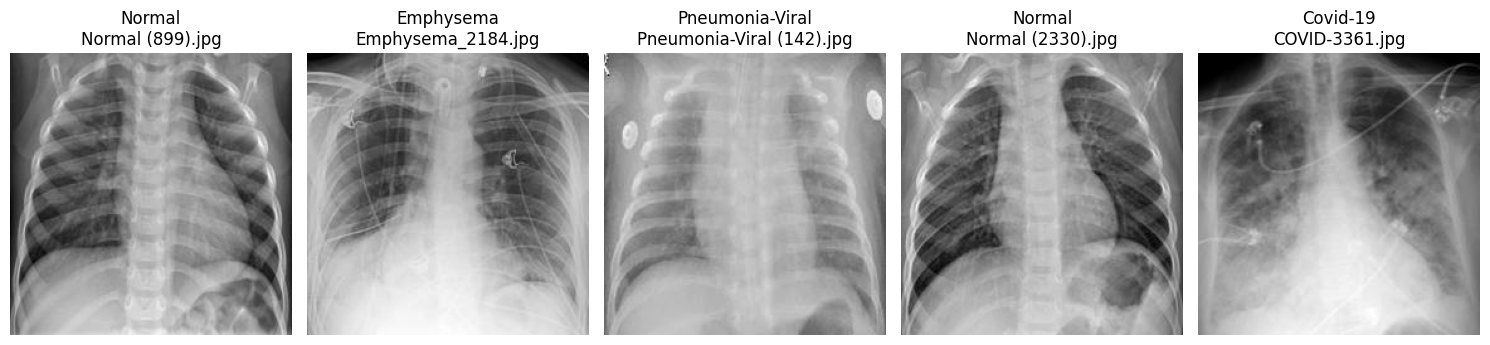

In [12]:
import pandas as pd

def count_images(path):
    counts = {}
    for cls in os.listdir(path):
        cls_path = os.path.join(path, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_path)
val_counts = count_images(val_path)
test_counts = count_images(test_path)

df = pd.DataFrame([train_counts, val_counts, test_counts],
                  index=["Train", "Val", "Test"]).fillna(0).astype(int)

df.T.plot(kind='bar', figsize=(12,6))
plt.title("Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Show 5 random sample images
def show_samples(path, n=5):
    classes = os.listdir(path)
    fig, axes = plt.subplots(1, n, figsize=(15,5))
    for i in range(n):
        cls = random.choice(classes)
        cls_path = os.path.join(path, cls)
        img_name = random.choice(os.listdir(cls_path))
        img_path = os.path.join(cls_path, img_name)
        img = plt.imread(img_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{cls}\n{img_name}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

show_samples(train_path, n=5)

In [13]:
from PIL import Image


mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]


train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])


val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

class ChestXRayDataset(Dataset):
    def __init__(self, root_dir, class_names, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = class_names
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        self.samples = []
        for cls in self.classes:
            cls_path = os.path.join(root_dir, cls)
            if not os.path.isdir(cls_path):
                continue
            for img_name in os.listdir(cls_path):
                self.samples.append((os.path.join(cls_path, img_name), self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label, img_path

train_dataset = ChestXRayDataset(train_path, CLASS_NAMES, transform=train_transform)
val_dataset = ChestXRayDataset(val_path, CLASS_NAMES, transform=val_transform)
test_dataset = ChestXRayDataset(test_path, CLASS_NAMES, transform=val_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 14551, Val: 1748, Test: 1737


In [14]:
from torchvision import models
model = models.convnext_tiny(weights="IMAGENET1K_V1")


num_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(num_features, NUM_CLASSES)

model.to(device)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 165MB/s] 


Total parameters: 27,824,742


In [17]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.cuda.amp import GradScaler, autocast

EPOCHS = 25
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = GradScaler()

/tmp/ipykernel_538/382598174.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [18]:
def train_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    pbar = tqdm(loader, desc="Training")
    for images, labels, _ in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        with autocast():  # Mixed precision forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        pbar.set_postfix({'loss': loss.item()})
    return total_loss / len(loader), 100. * correct / total

def validate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels, _ in tqdm(loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
    return total_loss / len(loader), 100. * correct / total

# Training history
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_acc = 0.0
patience_counter = 0

for epoch in range(1, EPOCHS+1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, scaler)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss: {train_loss:.2f}, Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.2f}, Val Acc: {val_acc:.2f}%")

    # Early stopping logic
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_convnext.pth")
        patience_counter = 0
        print(f"✓ New best model saved (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs.")
            break


Epoch 1/25


Training:   0%|          | 0/455 [00:00<?, ?it/s]/tmp/ipykernel_538/994927387.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():  # Mixed precision forward pass
Validating: 100%|██████████| 55/55 [00:11<00:00,  4.90it/s]


Train Loss: 0.54, Train Acc: 77.70%
Val Loss: 0.36, Val Acc: 85.53%
✓ New best model saved (Val Acc: 85.53%)

Epoch 2/25


Validating: 100%|██████████| 55/55 [00:08<00:00,  6.84it/s]


Train Loss: 0.44, Train Acc: 81.85%
Val Loss: 0.31, Val Acc: 87.30%
✓ New best model saved (Val Acc: 87.30%)

Epoch 3/25


...

Train Loss: 0.11, Train Acc: 95.66%
Val Loss: 0.17, Val Acc: 94.68%

Epoch 21/25


Validating: 100%|██████████| 55/55 [00:08<00:00,  6.23it/s]


Train Loss: 0.10, Train Acc: 96.12%
Val Loss: 0.18, Val Acc: 94.91%

Epoch 22/25


Validating: 100%|██████████| 55/55 [00:08<00:00,  6.27it/s]

Train Loss: 0.11, Train Acc: 95.80%
Val Loss: 0.16, Val Acc: 95.31%
Early stopping triggered after 22 epochs.


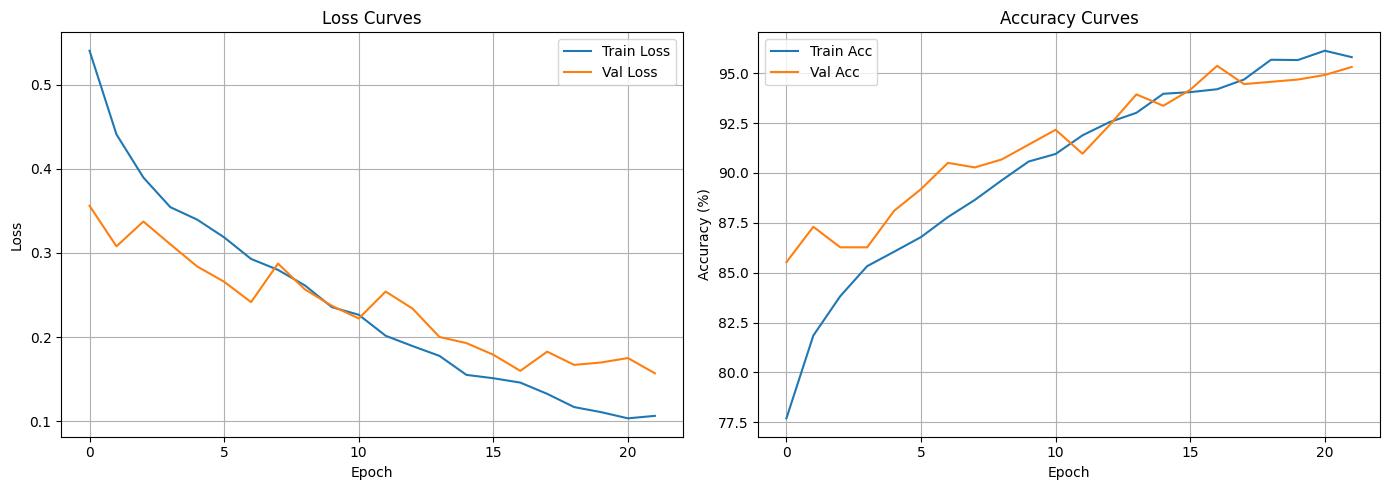

In [19]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curves')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curves')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Testing: 100%|██████████| 55/55 [00:22<00:00,  2.44it/s]



TEST SET EVALUATION - ConvNeXt-Tiny
Accuracy:  0.9597 (95.97%)
F1-Score (weighted): 0.9597
F1-Score (macro):    0.9606

Classification Report:
                     precision    recall  f1-score   support

           Covid-19       0.98      0.99      0.98       300
          Emphysema       0.99      0.98      0.98       250
             Normal       0.97      0.98      0.98       300
Pneumonia-Bacterial       0.93      0.91      0.92       300
    Pneumonia-Viral       0.90      0.91      0.90       300
       Tuberculosis       1.00      1.00      1.00       287

           accuracy                           0.96      1737
          macro avg       0.96      0.96      0.96      1737
       weighted avg       0.96      0.96      0.96      1737



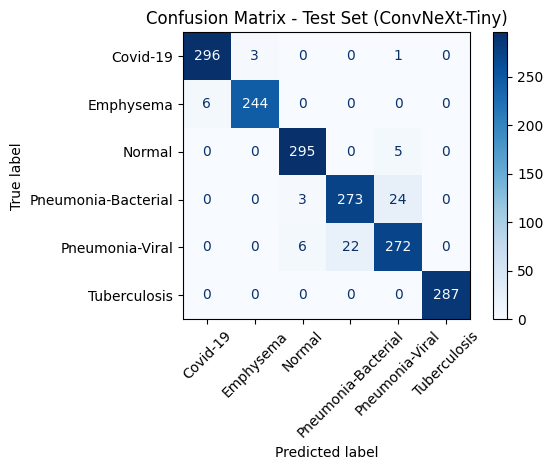

In [20]:
model.load_state_dict(torch.load("best_convnext.pth"))
model.eval()

all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels, _ in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

accuracy = accuracy_score(all_labels, all_preds)
f1_weighted = f1_score(all_labels, all_preds, average='weighted')
f1_macro = f1_score(all_labels, all_preds, average='macro')

print("\n" + "="*60)
print("TEST SET EVALUATION - ConvNeXt-Tiny")
print("="*60)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"F1-Score (weighted): {f1_weighted:.4f}")
print(f"F1-Score (macro):    {f1_macro:.4f}")

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix - Test Set (ConvNeXt-Tiny)")
plt.tight_layout()
plt.show()

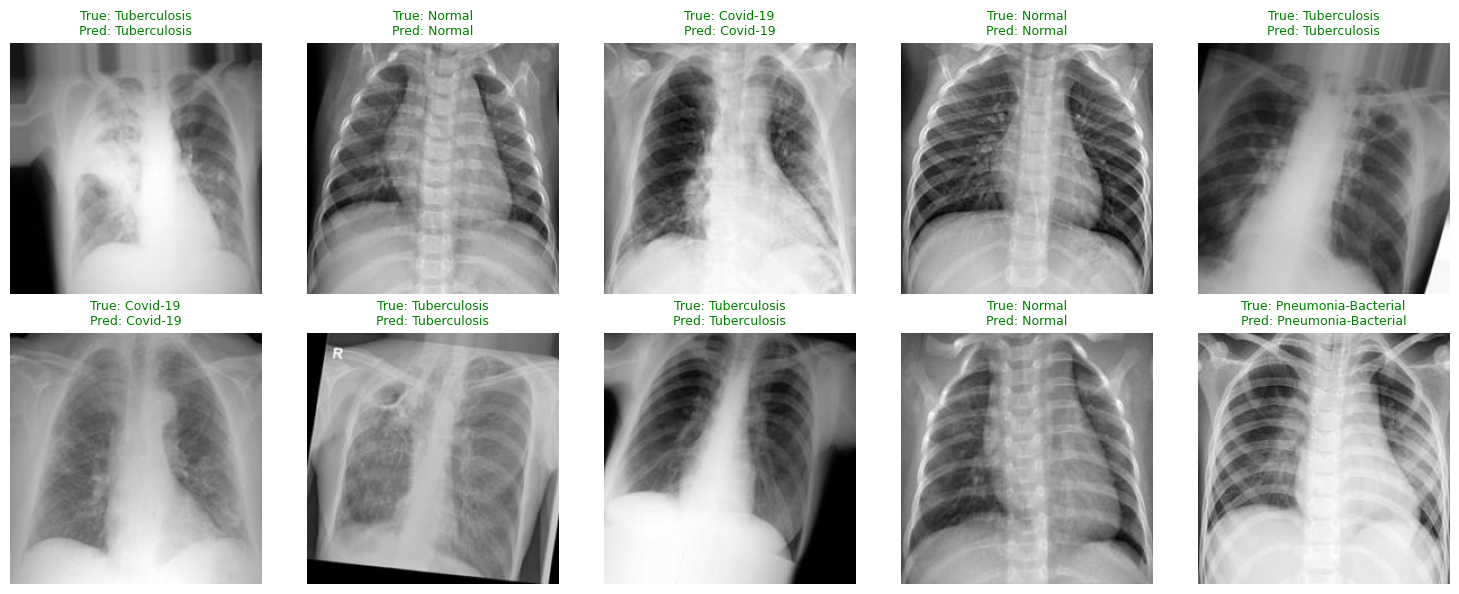

In [22]:
def show_random_predictions(model, dataset, class_names, num_images=10):
    model.eval()
    device = next(model.parameters()).device
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    indices = random.sample(range(len(dataset)), num_images)

    for i, idx in enumerate(indices):
        img_tensor, true_label, img_path = dataset[idx]
        orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        input_tensor = img_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            outputs = model(input_tensor)
            _, pred = outputs.max(1)

        true_name = class_names[true_label]
        pred_name = class_names[pred.item()]
        color = 'green' if true_label == pred.item() else 'red'

        axes[i].imshow(orig_img, cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(f"True: {true_name}\nPred: {pred_name}", color=color, fontsize=9)

    plt.tight_layout()
    plt.show()

show_random_predictions(model, test_dataset, CLASS_NAMES, num_images=10)

In [24]:
with open("class_names.pkl", "wb") as f:
    pickle.dump(CLASS_NAMES, f)

from google.colab import files
files.download("best_convnext.pth")
files.download("class_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>